# TiRex-2 Phase I — Bike-Sharing Forecasting & Model Behavior
**AI and Visualization Lab | JKU Linz | WS 2026/27**  
**Model:** `NX-AI/TiRex-2` pretrained zero-shot forecaster  
**Data:** Capital Bikeshare (Washington, DC) hourly trip starts merged with Open-Meteo weather  
**Collaborators:** Phase I pair — David-Ilknur

> **Seasonal extension (December 2023–June 2024):** Seven months of hourly bike trips and weather are aligned in UTC, with calendar features derived from Washington local time. Section 10 runs chronological rolling forecasts over the expanded period; Sections 11–12 investigate weather and demand conditions. Earlier execution outputs were cleared because they belong to the May–June experiment.
**Data provenance note:** The *provided* script actually downloads official [Capital Bikeshare monthly trip history](https://capitalbikeshare.com/system-data) from its S3 bucket, then merges [Open-Meteo historical weather](https://open-meteo.com/en/docs/historical-weather-api). CityBikes' historical records are station-status snapshots, not the individual trip files used here. This notebook follows the provided script's actual sources and target definition.

**External docs:** [TiRex-2 GitHub](https://github.com/NX-AI/tirex-2) · [TiRex-2 forecasting](https://nx-ai.github.io/tirex-2/how-to/forecasting/) · [TiRex-2 covariates](https://nx-ai.github.io/tirex-2/how-to/covariates/).

## 1. Project Introduction

### Research objective
Examine *how* TiRex-2 behaves when forecasting hourly bike-sharing demand, rather than only reporting aggregate forecasting scores. Initial experiments compare:

- **Calendar-only** forecast: target history plus hour/day features known in advance.
- **Calendar + past weather**: the same target and future-known calendar, with *past observed* temperature, precipitation, humidity, and wind speed added.

This is a controlled input comparison, **not** a causal test of weather effects. Avoid using observed weather during the held-out 24-hour horizon (that would leak future information). Actual future *weather forecasts* could be introduced in a later experiment if appropriately time-stamped and archived.

**Phase I** inspects inputs/outputs only.

## 2. Environment and GPU Check
CPU is also supported; the model download requires access to Hugging Face.

In [ ]:
import platform
import sys
import torch

print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print('GPU:', gpu.name)
    print('Compute capability:', torch.cuda.get_device_capability(0))
    print('GPU memory (GiB):', round(gpu.total_memory / (1024**3), 2))
else:
    print('Using CPU. GPU availability in free Colab is not guaranteed.')

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cpu
CUDA available: False
Using CPU. GPU availability in free Colab is not guaranteed.


## 3. Install Dependencies
Run once per new Colab runtime. **TiRex-2 uses `tirex-2`, not `tirex-ts`**, and its API differs from the original TiRex. If Colab requests a restart after pip installation, restart and rerun from Section 2.

In [ ]:
%pip install -q "tirex-2" "huggingface_hub" "pandas>=2.0" "numpy" "matplotlib" "seaborn" "scikit-learn"

## 4. Import Libraries & Paths
The CSVs and downloaded raw monthly ZIP files are cached in `data/`. Files in Colab's `/content` are temporary; optionally change `WORKDIR` to a **shared folder mounted from Google Drive** for persistence. Ensure both collaborators have access permissions.

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from tirex2 import TimeseriesType, load_model

WORKDIR = Path.cwd()   # Optional: set to a shared Google Drive path after mounting Drive.
DATA_DIR = WORKDIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print('Working directory:', WORKDIR)
print('Data directory:', DATA_DIR)
print('TiRex-2 imports OK.')

Working directory: /content
Data directory: /content/data
TiRex-2 imports OK.


## 5. Load Pretrained TiRex-2 Model

The official usage is `load_model("NX-AI/TiRex-2", device=...)`. No fine-tuning.

In [ ]:
# Optional: retrieve Hugging Face credentials securely from Colab Secrets.
try:
    from google.colab import userdata
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        os.environ['HF_TOKEN'] = hf_token   # Do not print the token.
except Exception:
    pass  # Public/gated authentication already configured or token not yet supplied.

MODEL_ID = 'NX-AI/TiRex-2'
FORCE_CPU = False
DEVICE = 'cuda' if torch.cuda.is_available() and not FORCE_CPU else 'cpu'
print('Loading:', MODEL_ID, '| device:', DEVICE)
try:
    model = load_model(MODEL_ID, device=DEVICE)
except Exception as exc:
    print('Model load failed. Check Hugging Face model access and HF_TOKEN;')
    print('if the error is CUDA-related, set FORCE_CPU=True and rerun.')
    raise
print('Pretrained TiRex-2 loaded successfully. No training performed.')

Loading: NX-AI/TiRex-2 | device: cpu


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Pretrained TiRex-2 loaded successfully. No training performed.


## 6. Generate or Load Bike-Sharing + Weather Data

### 6.1 Embedded version of the data-generation script

It retains official Capital Bikeshare monthly trip-file source and Open-Meteo weather merge.

- Uses an explicit start/end period (end **exclusive**) rather than automatically downloading every month from 2020–2026.
- Reads ZIPs in chunks and aggregates to an **hourly** table (`rides_started`), without producing the original memory-intensive station-by-day table.
- Caches raw ZIPs and exports `capital_hourly.csv` plus `weather_hourly.csv`.
- Preserves important weather columns and calendar context for later Vis4AI work.

**Default interval:** December 1, 2023–June 30, 2024 (end exclusive: July 1). This crosses the March 10, 2024 US daylight-saving change. Trip timestamps are interpreted as Washington local time and converted to UTC before aggregation; weather is requested in UTC. The final CSV uses hourly UTC timestamps, while calendar and holiday features use Washington local time. Downloading seven monthly archives can require substantial time and Colab disk space. These are historical observations, not current bike availability.

In [ ]:
%%writefile data_generation_colab.py
"""Colab-friendly hourly Capital Bikeshare + Open-Meteo data generator.

Adapted from the team's uploaded data_generation.py. The input is the official
Capital Bikeshare monthly trip-history ZIPs (not CityBikes station-status data).
This bounded version generates the hourly demand/weather table needed for the
first TiRex-2 forecasting experiment and avoids memory-intensive station tables.

Run: python data_generation_colab.py --start 2023-12-01 --end 2024-07-01 --outdir ./data
Dates are half-open: start inclusive, end exclusive, in Washington local time.
All hourly joins are performed using timezone-aware UTC timestamps.
"""
from __future__ import annotations

import argparse
import io
import json
from pathlib import Path
import urllib.error
import urllib.parse
import urllib.request
import zipfile

import numpy as np
import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

BASE_URL = "https://s3.amazonaws.com/capitalbikeshare-data"
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
LOCAL_TZ = "America/New_York"
COLUMN_ALIASES = {
    "started_at": ("started_at", "start date", "starttime", "start time", "started at"),
    "ended_at": ("ended_at", "end date", "endtime", "end time", "ended at"),
    "rideable_type": ("rideable_type", "bike type", "biketype"),
    "member_casual": ("member_casual", "member type", "usertype", "user type", "customer type"),
    "start_lat": ("start_lat", "start latitude"),
    "start_lng": ("start_lng", "start longitude"),
    "end_lat": ("end_lat", "end latitude"),
    "end_lng": ("end_lng", "end longitude"),
}


def normalize_columns(columns):
    available = {str(c).strip().lower(): c for c in columns}
    renames = {}
    for canonical, aliases in COLUMN_ALIASES.items():
        for alias in aliases:
            if alias in available:
                renames[available[alias]] = canonical
                break
    return renames


def month_starts(start: pd.Timestamp, end: pd.Timestamp):
    """Each source month overlapping the half-open date window."""
    current = start.to_period("M").to_timestamp()
    while current < end:
        yield current
        current += pd.DateOffset(months=1)


def download_month(month: pd.Timestamp, download_dir: Path) -> Path | None:
    name = f"{month.year}{month.month:02d}-capitalbikeshare-tripdata.zip"
    destination = download_dir / name
    if destination.exists() and zipfile.is_zipfile(destination):
        print(f"Using cached: {name}")
        return destination
    if destination.exists():
        destination.unlink()
    url = f"{BASE_URL}/{name}"
    print(f"Downloading: {url}", flush=True)
    try:
        urllib.request.urlretrieve(url, destination)
    except urllib.error.HTTPError as exc:
        if exc.code == 404:
            print(f"Monthly file not published: {name}")
            return None
        raise
    if not zipfile.is_zipfile(destination):
        raise ValueError(f"Invalid ZIP file downloaded: {destination}")
    return destination


def read_trip_chunks(archive_path: Path, chunksize: int = 200_000):
    with zipfile.ZipFile(archive_path) as archive:
        csv_members = [
            m for m in archive.namelist()
            if m.lower().endswith(".csv")
            and not m.startswith("__MACOSX/")
            and not Path(m).name.startswith("._")
        ]
        if not csv_members:
            raise ValueError(f"No CSV entries found in {archive_path.name}")
        for member in csv_members:
            with archive.open(member) as handle:
                yield from pd.read_csv(handle, chunksize=chunksize, low_memory=False)


def fetch_weather(start_utc: pd.Timestamp, end_utc: pd.Timestamp) -> pd.DataFrame:
    """Historical hourly weather in UTC, using half-open UTC time bounds."""
    params = {
        "latitude": 38.9072,
        "longitude": -77.0369,
        "start_date": start_utc.date().isoformat(),
        "end_date": (end_utc - pd.Timedelta(hours=1)).date().isoformat(),
        "timezone": "UTC",
        "wind_speed_unit": "kmh",
        "precipitation_unit": "mm",
        "hourly": ",".join([
            "temperature_2m", "relative_humidity_2m", "precipitation",
            "snowfall", "cloud_cover", "wind_speed_10m", "wind_gusts_10m",
        ]),
    }
    url = WEATHER_URL + "?" + urllib.parse.urlencode(params)
    print("Downloading historical hourly weather from Open-Meteo (UTC)...")
    with urllib.request.urlopen(url, timeout=180) as response:
        payload = json.load(response)
    if "hourly" not in payload:
        raise RuntimeError(f"Open-Meteo response missing hourly data: {payload}")
    weather = pd.DataFrame(payload["hourly"]).rename(columns={
        "time": "timestamp", "temperature_2m": "temp",
        "relative_humidity_2m": "humidity", "precipitation": "precip",
        "cloud_cover": "cloudcover", "wind_speed_10m": "windspeed",
        "wind_gusts_10m": "windgust",
    })
    weather["timestamp"] = pd.to_datetime(
        weather["timestamp"], errors="raise", utc=True
    )
    weather = weather.loc[
        (weather["timestamp"] >= start_utc) &
        (weather["timestamp"] < end_utc)
    ].copy()
    if weather["timestamp"].duplicated().any():
        raise ValueError("Duplicate UTC hourly weather timestamps")
    weather["is_rain"] = (weather["precip"] > 0.2).astype("int8")
    weather["is_heavy_rain"] = (weather["precip"] > 10).astype("int8")
    weather["is_snow"] = (weather["snowfall"] > 0).astype("int8")
    weather["weather_regime"] = np.select(
        [weather["is_snow"].eq(1), weather["is_heavy_rain"].eq(1), weather["is_rain"].eq(1)],
        ["snow", "heavy rain", "rain"], default="dry"
    )
    return weather


def build_dataset(start: str, end: str, outdir: str) -> Path:
    start_ts, end_ts = pd.Timestamp(start), pd.Timestamp(end)
    if pd.isna(start_ts) or pd.isna(end_ts) or end_ts <= start_ts:
        raise ValueError("Provide valid dates with --end after --start.")
    if (end_ts - start_ts).days > 92:
        print("Warning: more than 3 months of raw trips may be slow or memory-intensive on free Colab.")
    # Source trip times have no UTC offset and are interpreted as DC local time.
    # The requested half-open interval is converted to UTC, respecting the DST change.
    start_utc = start_ts.tz_localize(LOCAL_TZ).tz_convert("UTC")
    end_utc = end_ts.tz_localize(LOCAL_TZ).tz_convert("UTC")

    root = Path(outdir).expanduser().resolve()
    root.mkdir(parents=True, exist_ok=True)
    download_dir = root / "raw"
    download_dir.mkdir(exist_ok=True)
    chunks = []
    total_rows = 0

    for month in month_starts(start_ts, end_ts):
        archive = download_month(month, download_dir)
        if archive is None:
            continue
        for chunk in read_trip_chunks(archive):
            chunk = chunk.rename(columns=normalize_columns(chunk.columns))
            if "started_at" not in chunk:
                raise ValueError(f"No trip-start timestamp found in {archive.name}")
            start_naive = pd.to_datetime(
                chunk["started_at"], errors="coerce", format="mixed"
            )
            # Capital Bikeshare trip-file timestamps are treated as local DC time.
            # Nonexistent spring-forward times cannot be genuine local timestamps.
            # Ambiguous fall-back times (if included in later expansions) are
            # excluded rather than assigned an arbitrary UTC offset.
            start_local = start_naive.dt.tz_localize(
                LOCAL_TZ, nonexistent="NaT", ambiguous="NaT"
            )
            start_utc_values = start_local.dt.tz_convert("UTC")
            chunk = chunk.loc[
                (start_utc_values >= start_utc) &
                (start_utc_values < end_utc)
            ].copy()
            if chunk.empty:
                continue
            chunk["timestamp"] = start_utc_values.loc[chunk.index].dt.floor("h")
            if "member_casual" not in chunk:
                chunk["member_casual"] = ""
            if "rideable_type" not in chunk:
                chunk["rideable_type"] = ""
            member = chunk["member_casual"].fillna("").astype(str).str.lower()
            ride = chunk["rideable_type"].fillna("").astype(str).str.lower()
            chunk["member"] = member.str.contains("member|registered").astype("int8")
            chunk["casual"] = member.str.contains("casual|customer").astype("int8")
            chunk["electric"] = ride.str.contains("electric").astype("int8")
            summary = chunk.groupby("timestamp").agg(
                rides_started=("timestamp", "size"),
                member_rides=("member", "sum"),
                casual_rides=("casual", "sum"),
                electric_rides=("electric", "sum"),
            )
            chunks.append(summary)
            total_rows += len(chunk)
        print(f"Processed through {month:%Y-%m}; trip rows so far: {total_rows:,}")

    if not chunks:
        raise RuntimeError("No trip data found for the requested period. Try another published month.")
    hourly = pd.concat(chunks).groupby(level=0).sum()
    hourly = hourly.reindex(
        pd.date_range(start_utc, end_utc - pd.Timedelta(hours=1), freq="h", name="timestamp"),
        fill_value=0,
    ).reset_index()
    local_times = hourly["timestamp"].dt.tz_convert(LOCAL_TZ)
    hourly["date"] = local_times.dt.strftime("%Y-%m-%d")
    hourly["hour"] = local_times.dt.hour
    hourly["dow"] = local_times.dt.dayofweek
    hourly["month"] = local_times.dt.month
    hourly["is_weekend"] = (hourly["dow"] >= 5).astype("int8")
    holidays = USFederalHolidayCalendar().holidays(start=start_ts, end=end_ts)
    hourly["is_holiday"] = pd.to_datetime(hourly["date"]).isin(holidays).astype("int8")

    weather = fetch_weather(start_utc, end_utc)
    weather.to_csv(root / "weather_hourly.csv", index=False)
    hourly = hourly.merge(weather, on="timestamp", how="left", validate="one_to_one")
    if hourly["temp"].isna().any():
        print(f"Warning: {hourly['temp'].isna().sum()} hours lack weather; forecasting code checks selected context for missing values.")
    print("Expected UTC hourly intervals:", len(pd.date_range(start_utc, end_utc, freq="h", inclusive="left")))
    print("Local date interval:", start_ts.date(), "to", (end_ts - pd.Timedelta(days=1)).date())
    output = root / "capital_hourly.csv"
    hourly.to_csv(output, index=False)
    print(f"Saved {len(hourly):,} hourly rows -> {output}")
    return output


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--start", default="2023-12-01", help="Inclusive local YYYY-MM-DD")
    parser.add_argument("--end", default="2024-07-01", help="Exclusive local YYYY-MM-DD")
    parser.add_argument("--outdir", default="data", help="Directory for ZIP cache and output CSVs")
    args = parser.parse_args()
    build_dataset(args.start, args.end, args.outdir)


if __name__ == "__main__":
    main()

Overwriting data_generation_colab.py


### 6.2 Generate the hourly CSV (or reuse an already generated CSV)

- Default `DATA_MODE='generate'`: download the selected period's official trip files and archive weather; first run requires internet and may take time.
- `DATA_MODE='existing'`: reuse a prepared `capital_hourly.csv` in `DATA_DIR`, e.g. a shared group CSV; **does not download** data.
- `DATA_MODE='upload'`: upload a previously generated `capital_hourly.csv` from your local machine. Upload is Colab-only; use the data saved in Drive for persistent sharing.

In [ ]:
DATA_MODE = 'generate'     # 'generate', 'existing', or 'upload'
START_DATE = '2023-12-01'   # inclusive, local Washington date
END_DATE = '2024-07-01'     # exclusive

csv_path = DATA_DIR / 'capital_hourly.csv'

if DATA_MODE == 'generate':
    command = [
        sys.executable, 'data_generation_colab.py',
        '--start', START_DATE, '--end', END_DATE,
        '--outdir', str(DATA_DIR),
    ]
    print('Running:', ' '.join(command))
    subprocess.run(command, check=True)
elif DATA_MODE == 'upload':
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Upload exactly one generated hourly CSV.')
    import shutil
    source_path = Path(next(iter(uploaded)))
    if source_path.resolve() != csv_path.resolve():
        shutil.copy2(source_path, csv_path)
elif DATA_MODE != 'existing':
    raise ValueError('DATA_MODE must be generate, existing, or upload.')

if not csv_path.exists():
    raise FileNotFoundError(f'Hourly dataset not found at {csv_path}')
# Always regenerate or upload the CSV for the new interval.
# A May–June-only CSV from an earlier Colab session must NOT be reused.
print('CSV ready:', csv_path, '| size (MB):', round(csv_path.stat().st_size / (1024**2), 2))

Running: /usr/bin/python3 data_generation_colab.py --start 2023-12-01 --end 2024-07-01 --outdir /content/data
CSV ready: /content/data/capital_hourly.csv | size (MB): 0.49


### 6.3 Inspect generated dataset

This is the raw output of the team's data-generation logic.

In [ ]:
df_raw = pd.read_csv(csv_path)
print('Shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())
display(df_raw.head())
print('Missing values:')
display(df_raw.isna().sum().sort_values(ascending=False).to_frame('n_missing'))

Shape: (5111, 22)
Columns: ['timestamp', 'rides_started', 'member_rides', 'casual_rides', 'electric_rides', 'date', 'hour', 'dow', 'month', 'is_weekend', 'is_holiday', 'temp', 'humidity', 'precip', 'snowfall', 'cloudcover', 'windspeed', 'windgust', 'is_rain', 'is_heavy_rain', 'is_snow', 'weather_regime']


,timestamp,rides_started,member_rides,casual_rides,electric_rides,date,hour,dow,month,is_weekend,...,humidity,precip,snowfall,cloudcover,windspeed,windgust,is_rain,is_heavy_rain,is_snow,weather_regime
0,2023-12-01 05:00:00+00:00,142,93,49,97,2023-12-01,0,4,12,0,...,69,0.0,0.0,0,13.0,24.1,0,0,0,dry
1,2023-12-01 06:00:00+00:00,70,50,20,37,2023-12-01,1,4,12,0,...,70,0.0,0.0,27,12.4,23.4,0,0,0,dry
2,2023-12-01 07:00:00+00:00,34,18,16,25,2023-12-01,2,4,12,0,...,72,0.0,0.0,11,12.4,22.3,0,0,0,dry
3,2023-12-01 08:00:00+00:00,19,8,11,14,2023-12-01,3,4,12,0,...,74,0.0,0.0,100,9.6,22.3,0,0,0,dry
4,2023-12-01 09:00:00+00:00,23,14,9,21,2023-12-01,4,4,12,0,...,83,0.0,0.0,51,7.3,16.9,0,0,0,dry


Missing values:


,n_missing
timestamp,0
rides_started,0
member_rides,0
casual_rides,0
electric_rides,0
date,0
hour,0
dow,0
month,0
is_weekend,0


## 7. Initial Data Preparation & Validation

**Time zones:** `timestamp` is now an offset-aware UTC hour; local DC dates, hours and weekdays must be computed via `tz_convert('America/New_York')`. This avoids inventing a 02:00 hour during the March 2024 DST shift.

Target: `rides_started` (total trip **starts** per hour, not distinct riders and not bike availability). Timestamp: `timestamp` in local Washington time. The source uses local naive timestamps; DST-boundary months require a more careful UTC alignment than the simple example here.

Forecasting data must be chronological, hourly, and finite in the selected windows. Do not randomly shuffle time series.

In [ ]:
TIME_COLUMN = 'timestamp'
TARGET_COLUMN = 'rides_started'
WEATHER_COLUMNS = ['temp', 'precip', 'humidity', 'windspeed']
required = [TIME_COLUMN, TARGET_COLUMN, *WEATHER_COLUMNS]
missing_cols = sorted(set(required) - set(df_raw.columns))
if missing_cols:
    raise KeyError(f'Missing required columns: {missing_cols}')

df = df_raw.copy()
df[TIME_COLUMN] = pd.to_datetime(df[TIME_COLUMN], errors='raise', utc=True)
df = df.sort_values(TIME_COLUMN).reset_index(drop=True)
if df[TIME_COLUMN].duplicated().any():
    raise ValueError('Duplicate hourly timestamps detected. Review timezones/DST before inference.')
intervals = df[TIME_COLUMN].diff().dropna()
if not intervals.eq(pd.Timedelta(hours=1)).all():
    raise ValueError('Irregular hourly timestamps. Investigate missing/duplicate hours before inference.')
for col in [TARGET_COLUMN, *WEATHER_COLUMNS]:
    df[col] = pd.to_numeric(df[col], errors='coerce')
if (df[TARGET_COLUMN] < 0).any():
    raise ValueError('Bike-trip counts must be nonnegative.')

expected_start_utc = pd.Timestamp(START_DATE, tz='America/New_York').tz_convert('UTC')
expected_end_utc = pd.Timestamp(END_DATE, tz='America/New_York').tz_convert('UTC')
if (df[TIME_COLUMN].iloc[0] != expected_start_utc or
        df[TIME_COLUMN].iloc[-1] != expected_end_utc - pd.Timedelta(hours=1)):
    raise ValueError(
        'Loaded CSV does not match the selected date range. '
        'Regenerate/upload the December 2023–June 2024 dataset.'
    )
print('Time window (UTC):', df[TIME_COLUMN].min(), 'to', df[TIME_COLUMN].max())
print('Local start/end:', df[TIME_COLUMN].iloc[0].tz_convert('America/New_York'),
      'to', df[TIME_COLUMN].iloc[-1].tz_convert('America/New_York'))
print('Hourly rows:', len(df))
print('Missing target values:', int(df[TARGET_COLUMN].isna().sum()))
print('Missing weather values per column:')
print(df[WEATHER_COLUMNS].isna().sum().to_string())
display(df[[TIME_COLUMN, TARGET_COLUMN, *WEATHER_COLUMNS]].tail())

Time window (UTC): 2023-12-01 05:00:00+00:00 to 2024-07-01 03:00:00+00:00
Local start/end: 2023-12-01 00:00:00-05:00 to 2024-06-30 23:00:00-04:00
Hourly rows: 5111
Missing target values: 0
Missing weather values per column:
temp         0
precip       0
humidity     0
windspeed    0


,timestamp,rides_started,temp,precip,humidity,windspeed
5106,2024-06-30 23:00:00+00:00,958,26.7,0.1,76,11.9
5107,2024-07-01 00:00:00+00:00,907,25.7,0.2,85,12.3
5108,2024-07-01 01:00:00+00:00,613,25.8,0.1,93,5.8
5109,2024-07-01 02:00:00+00:00,513,25.2,0.0,96,5.6
5110,2024-07-01 03:00:00+00:00,284,24.8,0.0,87,13.7


## 8. Define Forecasting Experiment

**First controlled zero-shot experiment (editable):**

- Context: **336 hours** (previous two weeks).
- Horizon: **24 hours** (next day).
- The last 24 hours (June 30, 2024 local) are a chronological holdout used *only to check predictions*, not for training or as model covariate input. All timestamps are stored in UTC; calendar values are computed in DC local time.
- Compare two runs with identical context and **future-known calendar** information; add historical weather only to the second.
- In TiRex-2, target and `past_covariates` have shape `(n_features, context_length)`. `future_covariates` spans **context + horizon**; do not feed observed weather from the held-out horizon.
- All transformations below are deterministic. The model remains frozen.

Once we have a basic result, Phase I should extend beyond a single forecast window to multiple days and distinct weather regimes.

In [ ]:
CONTEXT_LENGTH = 336
PREDICTION_LENGTH = 24
if len(df) < CONTEXT_LENGTH + PREDICTION_LENGTH:
    raise ValueError('Not enough hourly observations for context + forecast horizon.')

origin = len(df) - PREDICTION_LENGTH
history = df.iloc[origin-CONTEXT_LENGTH:origin].copy()
future = df.iloc[origin:origin+PREDICTION_LENGTH].copy()
calendar_window = df.iloc[origin-CONTEXT_LENGTH:origin+PREDICTION_LENGTH].copy()

# These calendar features are truly known over the forecast horizon.
calendar_ts = calendar_window[TIME_COLUMN].dt.tz_convert('America/New_York')
hour = calendar_ts.dt.hour.to_numpy()
dow = calendar_ts.dt.dayofweek.to_numpy()
calendar_features = np.stack([
    np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24),
    np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7),
    (dow >= 5).astype(float),
]).astype(np.float32)

values_to_check = history[[TARGET_COLUMN, *WEATHER_COLUMNS]].to_numpy(dtype=np.float32)
if not np.isfinite(values_to_check).all():
    raise ValueError('History includes missing/non-finite target or weather values. Select a complete period; do not fill silently.')

# Crucially: future observed target/weather remain OUTSIDE model inputs.
target_tensor = torch.tensor(history[TARGET_COLUMN].to_numpy(dtype=np.float32)).unsqueeze(0)
past_weather_tensor = torch.tensor(history[WEATHER_COLUMNS].to_numpy(dtype=np.float32).T)
known_calendar_tensor = torch.tensor(calendar_features)

assert target_tensor.shape == (1, CONTEXT_LENGTH)
assert past_weather_tensor.shape == (len(WEATHER_COLUMNS), CONTEXT_LENGTH)
assert known_calendar_tensor.shape == (5, CONTEXT_LENGTH + PREDICTION_LENGTH)

print('Last observed hour:', history[TIME_COLUMN].iloc[-1])
print('Forecast interval:', future[TIME_COLUMN].iloc[0], '→', future[TIME_COLUMN].iloc[-1])
print('Target:', tuple(target_tensor.shape))
print('Past weather:', tuple(past_weather_tensor.shape))
print('Future-known calendar:', tuple(known_calendar_tensor.shape))

Last observed hour: 2024-06-30 03:00:00+00:00
Forecast interval: 2024-06-30 04:00:00+00:00 → 2024-07-01 03:00:00+00:00
Target: (1, 336)
Past weather: (4, 336)
Future-known calendar: (5, 360)


## 9. Run TiRex-2 Forecasting — Real Data

The model predicts nine quantiles (`0.1` to `0.9`); quantile index `4` is the **median**. The first test compares the same forecast horizon with/without *historical* weather covariates, while keeping future calendar features fixed. It saves results to CSV for later visualization and makes one **sanity-check plot**, not a complete Phase I investigation.

**If inference fails due to GPU-specific compatibility**, set `FORCE_CPU=True` in Section 5 and rerun. No weights are trained.

In [ ]:
calendar_only_ts = TimeseriesType(
    target=target_tensor,
    past_covariates=None,
    future_covariates=known_calendar_tensor,
)
calendar_weather_ts = TimeseriesType(
    target=target_tensor,
    past_covariates=past_weather_tensor,
    future_covariates=known_calendar_tensor,
)

with torch.inference_mode():
    outputs = model.forecast(
        [calendar_only_ts, calendar_weather_ts],
        prediction_length=PREDICTION_LENGTH,
        output_type='numpy',
    )

if len(outputs) != 2:
    raise RuntimeError(f'Expected 2 model outputs; got {len(outputs)}')
for result in outputs:
    if result.shape != (1, 9, PREDICTION_LENGTH):
        raise RuntimeError(f'Unexpected TiRex-2 output shape: {result.shape}')

actual = future[TARGET_COLUMN].to_numpy(dtype=float)
predictions = pd.DataFrame({
    'timestamp': future[TIME_COLUMN].to_numpy(),
    'actual_rides': actual,
    'calendar_only_p10': outputs[0][0, 0, :],
    'calendar_only_p50': outputs[0][0, 4, :],
    'calendar_only_p90': outputs[0][0, 8, :],
    'weather_past_p10': outputs[1][0, 0, :],
    'weather_past_p50': outputs[1][0, 4, :],
    'weather_past_p90': outputs[1][0, 8, :],
    # Observed future weather is attached ONLY AFTER forecasting for diagnosis.
    'observed_precip': future['precip'].to_numpy(),
    'observed_temp': future['temp'].to_numpy(),
})
for key in ['calendar_only', 'weather_past']:
    predictions[key + '_error'] = predictions[key + '_p50'] - predictions['actual_rides']

save_path = DATA_DIR / 'tirex2_first_forecast.csv'
predictions.to_csv(save_path, index=False)
display(predictions.head())
print('Saved predictions:', save_path)
if np.isfinite(actual).all():
    for key in ['calendar_only', 'weather_past']:
        mae = np.mean(np.abs(predictions[key + '_p50'].to_numpy() - actual))
        print(f'{key} first-window MAE: {mae:.2f} trips/hour (illustrative single-window metric only)')
else:
    print('Actuals missing: skipped numeric error check.')

,timestamp,actual_rides,calendar_only_p10,calendar_only_p50,calendar_only_p90,weather_past_p10,weather_past_p50,weather_past_p90,observed_precip,observed_temp,calendar_only_error,weather_past_error
0,2024-06-30 04:00:00+00:00,448.0,317.395233,393.738708,474.631287,320.641022,393.539764,469.617035,0.0,27.4,-54.261292,-54.460236
1,2024-06-30 05:00:00+00:00,343.0,138.061478,228.934998,324.996643,138.580872,224.155396,313.514709,0.0,27.2,-114.065002,-118.844604
2,2024-06-30 06:00:00+00:00,164.0,46.373398,146.115662,237.242493,43.910316,139.927673,223.378891,0.0,26.8,-17.884338,-24.072327
3,2024-06-30 07:00:00+00:00,81.0,8.309944,107.431885,214.263199,5.240685,98.665100,196.761566,0.0,26.6,26.431885,17.665100
4,2024-06-30 08:00:00+00:00,38.0,-1.985992,95.991455,197.518219,-4.154793,90.141724,180.157715,0.0,26.3,57.991455,52.141724


Saved predictions: /content/data/tirex2_first_forecast.csv
calendar_only first-window MAE: 59.97 trips/hour (illustrative single-window metric only)
weather_past first-window MAE: 56.09 trips/hour (illustrative single-window metric only)


## 10. Visualize Forecasting Behavior
**Implemented for the initial study; extend with additional interactive analysis as needed.** Identify *systematic* failure patterns across many chronological windows and visualize **when and how** the model fails, not just one aggregate score. Consider interactive time filters and forecast-error distributions.

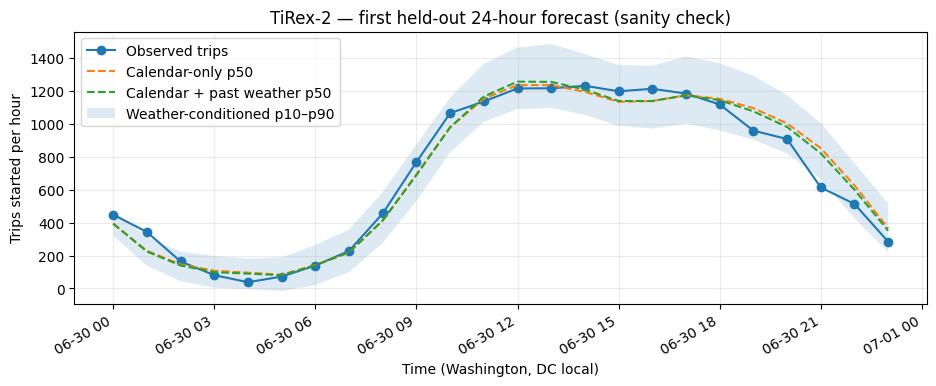

In [ ]:
# Quick output sanity check only. Full behavioral visual analytics belongs to Section 10.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pd.to_datetime(predictions['timestamp'], utc=True).dt.tz_convert('America/New_York'), predictions['actual_rides'], 'o-', label='Observed trips')
ax.plot(pd.to_datetime(predictions['timestamp'], utc=True).dt.tz_convert('America/New_York'), predictions['calendar_only_p50'], '--', label='Calendar-only p50')
ax.plot(pd.to_datetime(predictions['timestamp'], utc=True).dt.tz_convert('America/New_York'), predictions['weather_past_p50'], '--', label='Calendar + past weather p50')
ax.fill_between(
    pd.to_datetime(predictions['timestamp'], utc=True).dt.tz_convert('America/New_York'), predictions['weather_past_p10'], predictions['weather_past_p90'],
    alpha=0.15, label='Weather-conditioned p10–p90'
)
ax.set(title='TiRex-2 — first held-out 24-hour forecast (sanity check)',
       xlabel='Time (Washington, DC local)', ylabel='Trips started per hour')
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.show()
plot_path = DATA_DIR / '24H_forecast_plot.png'
fig.savefig(plot_path)



### 10.1 — Rolling Forecasts
The expanded 7-month dataset crosses the US March 2024 DST transition. Forecast origins are selected at **local midnight**; the 23-hour DST-change day is skipped to keep 24-hour daily evaluations comparable. To cover the full period, 64 valid daily origins are sampled evenly by default; raise `N_BACKTEST_DAYS` or use `None` for more dates.


In [ ]:

# Section 10.1 — Washington DC rolling forecasts
# Run Sections 1–9 first.

N_BACKTEST_DAYS = None  # Spread across winter, spring, summer; None = all eligible days

valid_origins_dc = []

for i in range(
    CONTEXT_LENGTH,
    len(df) - PREDICTION_LENGTH + 1
):
    # Forecast entire Washington local days, not UTC calendar days.
    test_local_hours = df[TIME_COLUMN].iloc[i:i+PREDICTION_LENGTH].dt.tz_convert(
        'America/New_York'
    )
    if test_local_hours.iloc[0].hour != 0:
        continue
    # Spring-forward day has only 23 local hours. Skip that date so
    # every evaluated forecast has exactly hours 00:00 through 23:00.
    if (test_local_hours.dt.date.nunique() != 1 or
            sorted(test_local_hours.dt.hour.tolist()) != list(range(24))):
        continue

    hist = df.iloc[i-CONTEXT_LENGTH:i]
    test = df.iloc[i:i+PREDICTION_LENGTH]

    history_values = hist[
        [TARGET_COLUMN, *WEATHER_COLUMNS]
    ].to_numpy(dtype=float)

    future_values = test[
        TARGET_COLUMN
    ].to_numpy(dtype=float)

    if (np.isfinite(history_values).all()
            and np.isfinite(future_values).all()):
        valid_origins_dc.append(i)

if not valid_origins_dc:
    raise ValueError("No valid forecasting windows.")

n = (
    len(valid_origins_dc)
    if N_BACKTEST_DAYS is None
    else min(N_BACKTEST_DAYS, len(valid_origins_dc))
)

positions = np.unique(
    np.linspace(0, len(valid_origins_dc)-1, n, dtype=int)
)

selected_dc = [valid_origins_dc[j] for j in positions]

print(f"Running {len(selected_dc)} of "
      f"{len(valid_origins_dc)} eligible days.")

records_dc = []

for k, i in enumerate(selected_dc, start=1):

    hist = df.iloc[i-CONTEXT_LENGTH:i]
    test = df.iloc[i:i+PREDICTION_LENGTH]

    times = df[TIME_COLUMN].iloc[
        i-CONTEXT_LENGTH:i+PREDICTION_LENGTH
    ].dt.tz_convert('America/New_York')

    hour = times.dt.hour.to_numpy()
    dow = times.dt.dayofweek.to_numpy()

    calendar_features_dc = np.stack([
        np.sin(2*np.pi*hour/24),
        np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*dow/7),
        np.cos(2*np.pi*dow/7),
        (dow >= 5).astype(np.float32),
    ]).astype(np.float32)

    target_dc = torch.tensor(
        hist[TARGET_COLUMN].to_numpy(
            dtype=np.float32
        )[None, :]
    )

    weather_dc = torch.tensor(
        hist[WEATHER_COLUMNS].to_numpy(
            dtype=np.float32
        ).T.copy()
    )

    calendar_dc = torch.tensor(calendar_features_dc)

    # Experiment A: Calendar only
    baseline = TimeseriesType(
        target=target_dc,
        past_covariates=None,
        future_covariates=calendar_dc
    )

    # Experiment B: Calendar + historical weather
    conditioned = TimeseriesType(
        target=target_dc,
        past_covariates=weather_dc,
        future_covariates=calendar_dc
    )

    with torch.inference_mode():
        outputs = model.forecast(
            [baseline, conditioned],
            prediction_length=PREDICTION_LENGTH,
            output_type="numpy"
        )

    base_out, weather_out = [
        np.asarray(x) for x in outputs
    ]

    expected = (1, 9, PREDICTION_LENGTH)
    if base_out.shape != expected or weather_out.shape != expected:
        raise ValueError("Unexpected TiRex-2 output shape.")

    records_dc.append(pd.DataFrame({
        "date": test[TIME_COLUMN].iloc[0].tz_convert('America/New_York').strftime("%Y-%m-%d"),
        "timestamp": test[TIME_COLUMN].to_numpy(),  # UTC
        "hour_local": test[TIME_COLUMN].dt.tz_convert('America/New_York').dt.hour.to_numpy(),
        "actual": test[TARGET_COLUMN].to_numpy(dtype=float),
        "calendar_p50": base_out[0, 4, :],
        "weather_p10": weather_out[0, 0, :],
        "weather_p50": weather_out[0, 4, :],
        "weather_p90": weather_out[0, 8, :],
        "observed_precip": test["precip"].to_numpy(dtype=float)
    }))

    if k % 10 == 0 or k == len(selected_dc):
        print(f"Completed {k}/{len(selected_dc)} days")

rolling_dc = pd.concat(records_dc, ignore_index=True)

rolling_dc["calendar_error"] = (
    rolling_dc["calendar_p50"] - rolling_dc["actual"]
)

rolling_dc["weather_error"] = (
    rolling_dc["weather_p50"] - rolling_dc["actual"]
)

rolling_dc["inside_p10_p90"] = rolling_dc["actual"].between(
    rolling_dc["weather_p10"],
    rolling_dc["weather_p90"]
)

rolling_dc.to_csv(
    DATA_DIR / "dc_rolling_hourly_predictions.csv",
    index=False
)

display(rolling_dc.head())


Running 198 of 198 eligible days.
Completed 10/198 days
Completed 20/198 days
Completed 30/198 days
Completed 40/198 days
Completed 50/198 days
Completed 60/198 days
Completed 70/198 days
Completed 80/198 days
Completed 90/198 days
Completed 100/198 days
Completed 110/198 days
Completed 120/198 days
Completed 130/198 days
Completed 140/198 days
Completed 150/198 days
Completed 160/198 days
Completed 170/198 days
Completed 180/198 days
Completed 190/198 days
Completed 198/198 days


,date,timestamp,hour_local,actual,calendar_p50,weather_p10,weather_p50,weather_p90,observed_precip,calendar_error,weather_error,inside_p10_p90
0,2023-12-15,2023-12-15 05:00:00+00:00,0,121.0,121.516296,91.225822,124.993744,160.979614,0.0,0.516296,3.993744,True
1,2023-12-15,2023-12-15 06:00:00+00:00,1,75.0,48.150543,15.346245,50.982086,93.895287,0.0,-26.849457,-24.017914,True
2,2023-12-15,2023-12-15 07:00:00+00:00,2,34.0,20.420013,-23.009918,23.329559,63.873749,0.0,-13.579987,-10.670441,True
3,2023-12-15,2023-12-15 08:00:00+00:00,3,16.0,15.496521,-28.974701,17.442474,69.912994,0.0,-0.503479,1.442474,True
4,2023-12-15,2023-12-15 09:00:00+00:00,4,18.0,31.704132,-17.075382,31.965515,84.014748,0.0,13.704132,13.965515,True


### 10.2 — Daily Forecast Error Analysis

Calendar-only MAE: 116.63
Calendar + past weather MAE: 116.49
p10–p90 empirical coverage: 78.6%
Days improved by past weather: 109 / 198


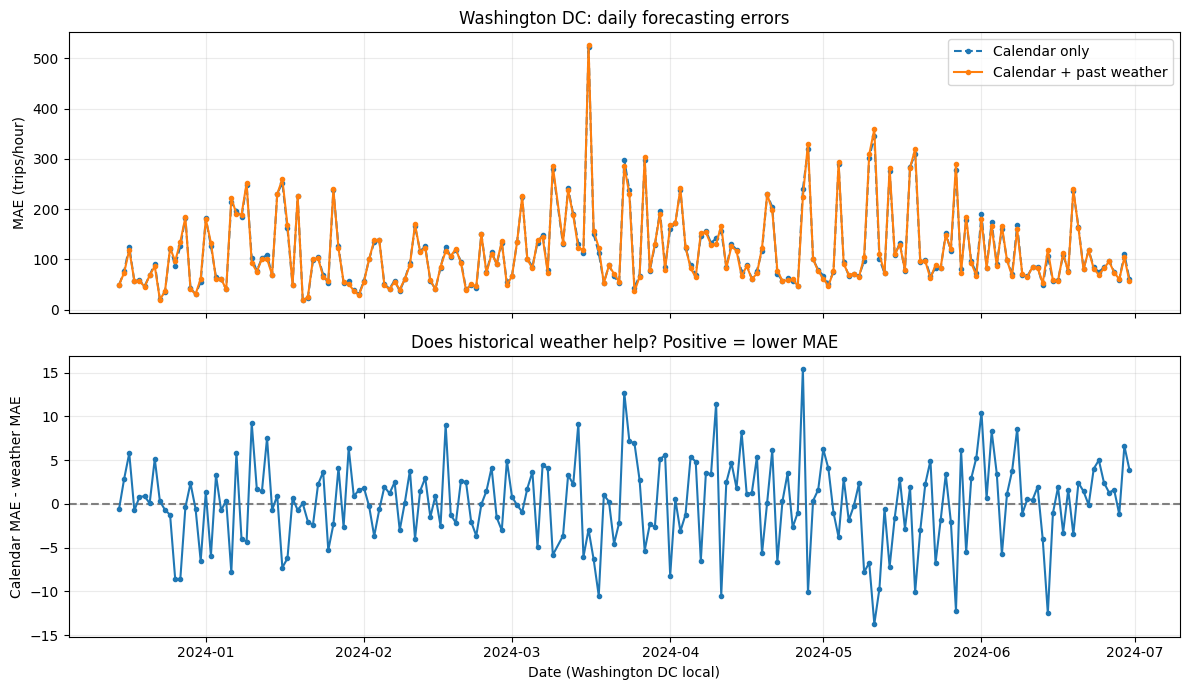

In [ ]:

# Section 10.2 — Daily forecasting errors

daily_dc = rolling_dc.groupby(
    "date", as_index=False
).agg(
    calendar_mae=(
        "calendar_error", lambda s: s.abs().mean()
    ),
    weather_mae=(
        "weather_error", lambda s: s.abs().mean()
    ),
    calendar_bias=("calendar_error", "mean"),
    weather_bias=("weather_error", "mean"),
    coverage80=("inside_p10_p90", "mean"),
    observed_total=("actual", "sum"),
    observed_precip_total=("observed_precip", "sum")
)

daily_dc["weather_improvement"] = (
    daily_dc["calendar_mae"] - daily_dc["weather_mae"]
)

daily_dc["date"] = pd.to_datetime(daily_dc["date"])

daily_dc.to_csv(
    DATA_DIR / "dc_rolling_daily_metrics.csv",
    index=False
)

print(
    "Calendar-only MAE:",
    round(rolling_dc["calendar_error"].abs().mean(), 2)
)
print(
    "Calendar + past weather MAE:",
    round(rolling_dc["weather_error"].abs().mean(), 2)
)
print(
    "p10–p90 empirical coverage:",
    f"{rolling_dc['inside_p10_p90'].mean():.1%}"
)
print(
    "Days improved by past weather:",
    (daily_dc["weather_improvement"] > 0).sum(),
    "/", len(daily_dc)
)

fig, ax = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True
)

ax[0].plot(
    daily_dc["date"], daily_dc["calendar_mae"],
    "o--", markersize=3, label="Calendar only"
)
ax[0].plot(
    daily_dc["date"], daily_dc["weather_mae"],
    "o-", markersize=3, label="Calendar + past weather"
)
ax[0].set(
    ylabel="MAE (trips/hour)",
    title="Washington DC: daily forecasting errors"
)
ax[0].legend()

ax[1].axhline(0, color="gray", linestyle="--")
ax[1].plot(
    daily_dc["date"],
    daily_dc["weather_improvement"],
    "o-", markersize=3
)
ax[1].set(
    xlabel="Date (Washington DC local)",
    ylabel="Calendar MAE - weather MAE",
    title="Does historical weather help? Positive = lower MAE"
)

for a in ax:
    a.grid(alpha=0.25)

fig.tight_layout()
plt.show()
plot_path = DATA_DIR / 'MAE.png'
fig.savefig(plot_path)


### 10.3 — Systematic Hourly Errors and Heatmap

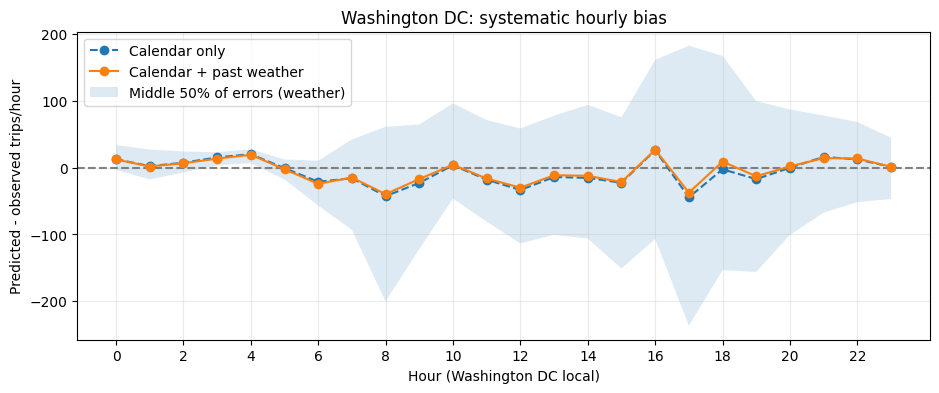

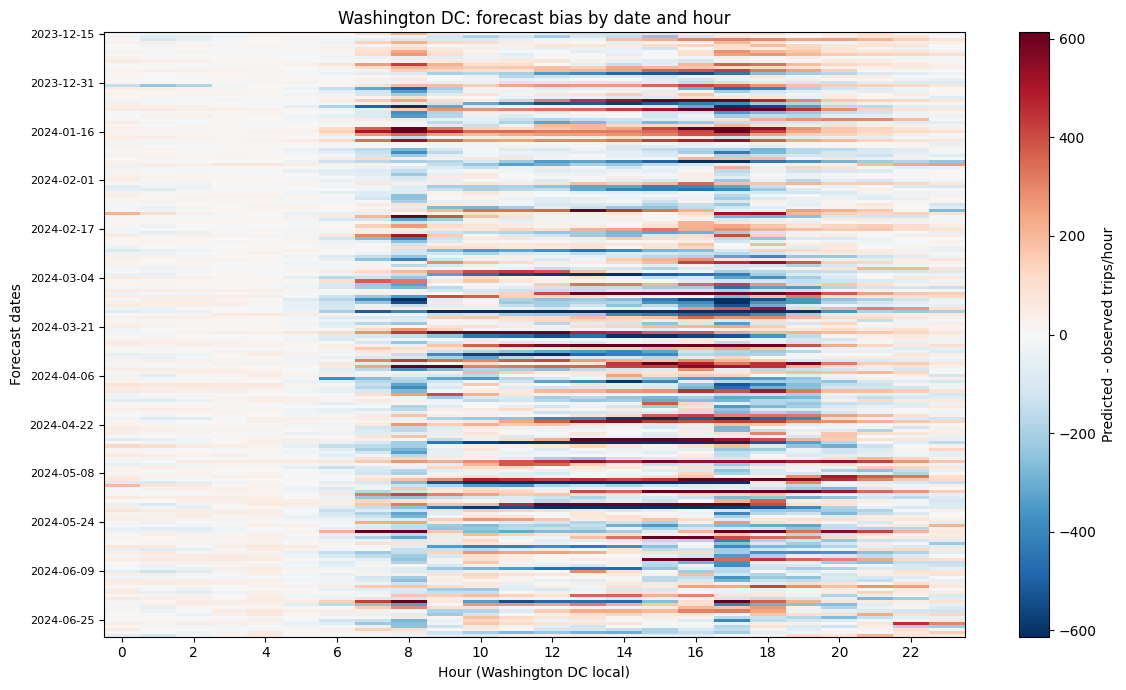

In [ ]:

# Section 10.3 — Hourly bias and date-hour heatmap

hour_profile_dc = rolling_dc.groupby(
    "hour_local"
).agg(
    calendar_bias=("calendar_error", "mean"),
    weather_bias=("weather_error", "mean"),
    q25=("weather_error", lambda s: s.quantile(.25)),
    q75=("weather_error", lambda s: s.quantile(.75))
).reindex(range(24))

fig, ax = plt.subplots(figsize=(11, 4))

ax.axhline(0, color="gray", linestyle="--")

ax.plot(
    hour_profile_dc.index,
    hour_profile_dc["calendar_bias"],
    "o--", label="Calendar only"
)
ax.plot(
    hour_profile_dc.index,
    hour_profile_dc["weather_bias"],
    "o-", label="Calendar + past weather"
)

ax.fill_between(
    hour_profile_dc.index.to_numpy(),
    hour_profile_dc["q25"].to_numpy(),
    hour_profile_dc["q75"].to_numpy(),
    alpha=0.15,
    label="Middle 50% of errors (weather)"
)

ax.set(
    xlabel="Hour (Washington DC local)",
    ylabel="Predicted - observed trips/hour",
    title="Washington DC: systematic hourly bias"
)
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

# Date-by-hour error heatmap

error_map_dc = rolling_dc.pivot(
    index="date",
    columns="hour_local",
    values="weather_error"
).reindex(columns=range(24))

fig, ax = plt.subplots(figsize=(12, 7))

lim = max(
    1,
    float(np.nanpercentile(
        np.abs(error_map_dc.to_numpy()), 98
    ))
)

im = ax.imshow(
    error_map_dc.to_numpy(),
    aspect="auto",
    cmap="RdBu_r",
    vmin=-lim,
    vmax=lim
)

ax.set(
    xlabel="Hour (Washington DC local)",
    ylabel="Forecast dates",
    title="Washington DC: forecast bias by date and hour"
)

ax.set_xticks(range(0, 24, 2))

step = max(1, len(error_map_dc) // 12)
ax.set_yticks(np.arange(0, len(error_map_dc), step))
ax.set_yticklabels(error_map_dc.index[::step], fontsize=8)

fig.colorbar(
    im, ax=ax,
    label="Predicted - observed trips/hour"
)

plt.tight_layout()
plt.show()
plot_path = DATA_DIR / 'forecast_bias.png'
fig.savefig(plot_path)


## 11. Weather-Based Error Analysis
**Implemented:** Analyze errors stratified by temperature, precipitation, wind, time of day and season. Compare calendar-only vs calendar-plus-past-weather fairly. Weather is observational and may be confounded with season, events, and weekday. Never use hindsight weather as a future-known covariate.

### 11.1 — Forecast errors under different weather conditions

Forecast errors by precipitation:


,rain_category,n_hours,calendar_mae,weather_mae,mean_improvement
0,Dry (<=0.2 mm),4298,107.873149,107.442797,0.430352
1,Light rain (0.2–2 mm),355,187.980824,190.403875,-2.423051
2,More rain (>2 mm),99,240.727404,244.301865,-3.574461


Forecast errors by temperature:


,temp_category,n_hours,calendar_mae,weather_mae,mean_improvement
0,<0°C,463,81.856438,82.398487,-0.542050
1,0–10°C,1766,92.905453,92.802095,0.103358
2,10–20°C,1503,140.847860,141.440630,-0.592770
3,20–30°C,894,139.037496,137.560139,1.477356
4,>=30°C,126,128.885583,126.709291,2.176292


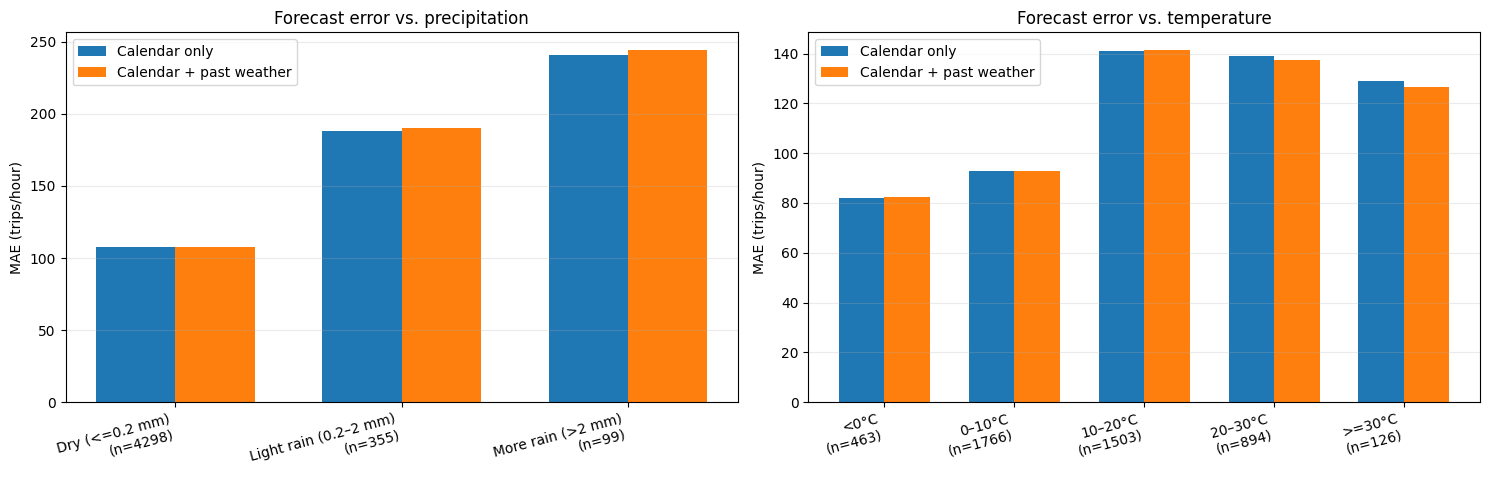

In [ ]:

# Join the observed weather at each forecast hour.
# Future observed weather is used for retrospective evaluation ONLY.

weather_lookup = df[
    [TIME_COLUMN, "temp", "precip", "humidity", "windspeed"]
].copy()

weather_lookup = weather_lookup.rename(
    columns={TIME_COLUMN: "timestamp"}
)

weather_lookup["timestamp"] = pd.to_datetime(
    weather_lookup["timestamp"]
)

wx_eval_dc = rolling_dc.copy()
wx_eval_dc["timestamp"] = pd.to_datetime(
    wx_eval_dc["timestamp"]
)

wx_eval_dc = wx_eval_dc.merge(
    weather_lookup,
    on="timestamp",
    how="left",
    validate="many_to_one"
)

wx_eval_dc["calendar_abs_error"] = (
    wx_eval_dc["calendar_error"].abs()
)

wx_eval_dc["weather_abs_error"] = (
    wx_eval_dc["weather_error"].abs()
)

# Positive improvement means that adding historical
# weather reduced the absolute forecasting error.
wx_eval_dc["weather_improvement"] = (
    wx_eval_dc["calendar_abs_error"]
    - wx_eval_dc["weather_abs_error"]
)

# Hourly precipitation categories (mm/hour).
wx_eval_dc["rain_category"] = pd.cut(
    wx_eval_dc["precip"],
    bins=[-np.inf, 0.2, 2.0, np.inf],
    labels=[
        "Dry (<=0.2 mm)",
        "Light rain (0.2–2 mm)",
        "More rain (>2 mm)"
    ]
)

# Temperature categories (degrees Celsius).
wx_eval_dc["temp_category"] = pd.cut(
    wx_eval_dc["temp"],
    bins=[-np.inf, 0, 10, 20, 30, np.inf],
    labels=[
        "<0°C", "0–10°C", "10–20°C",
        "20–30°C", ">=30°C"
    ],
    right=False
)

def summarize_weather_errors(data, group_col):
    return (
        data.groupby(group_col, observed=True)
        .agg(
            n_hours=("actual", "size"),
            calendar_mae=("calendar_abs_error", "mean"),
            weather_mae=("weather_abs_error", "mean"),
            mean_improvement=("weather_improvement", "mean")
        )
        .reset_index()
    )

rain_stats_dc = summarize_weather_errors(
    wx_eval_dc, "rain_category"
)

temp_stats_dc = summarize_weather_errors(
    wx_eval_dc, "temp_category"
)

print("Forecast errors by precipitation:")
display(rain_stats_dc)

print("Forecast errors by temperature:")
display(temp_stats_dc)

# Visualize the conditional MAE for both configurations.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, stats, category, title in [
    (
        axes[0], rain_stats_dc, "rain_category",
        "Forecast error vs. precipitation"
    ),
    (
        axes[1], temp_stats_dc, "temp_category",
        "Forecast error vs. temperature"
    )
]:
    x = np.arange(len(stats))
    width = 0.35

    ax.bar(
        x - width / 2,
        stats["calendar_mae"],
        width,
        label="Calendar only"
    )

    ax.bar(
        x + width / 2,
        stats["weather_mae"],
        width,
        label="Calendar + past weather"
    )

    labels = [
        f"{cat}\n(n={count})"
        for cat, count in zip(
            stats[category], stats["n_hours"]
        )
    ]

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=15, ha="right")
    ax.set_ylabel("MAE (trips/hour)")
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

plot_path = DATA_DIR / 'temp.png'
fig.savefig(plot_path)


### 11.2 — Does past weather actually improve the forecasts?

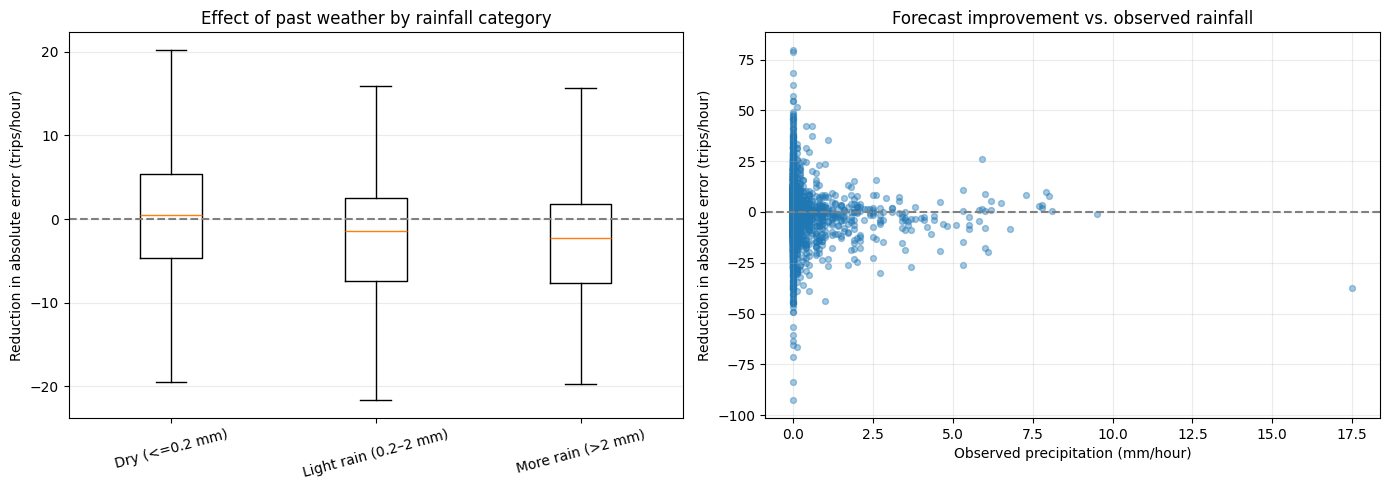

Mean absolute-error improvement: +0.134 trips/hour
Positive means historical weather helped; negative means it worsened predictions.


In [ ]:

# Compare errors on exactly the same forecast hours.
# Positive values: historical weather improves the forecast.
# Negative values: historical weather worsens the forecast.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Improvement by precipitation category
rain_groups = [
    wx_eval_dc.loc[
        wx_eval_dc["rain_category"] == category,
        "weather_improvement"
    ].dropna().to_numpy()
    for category in rain_stats_dc["rain_category"]
]

axes[0].boxplot(
    rain_groups,
    tick_labels=[
        str(x) for x in rain_stats_dc["rain_category"]
    ],
    showfliers=False
)

axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(
    title="Effect of past weather by rainfall category",
    ylabel="Reduction in absolute error (trips/hour)"
)
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.25)

# Plot B: Hourly rain vs. improvement
valid = wx_eval_dc[
    ["precip", "weather_improvement"]
].replace([np.inf, -np.inf], np.nan).dropna()

axes[1].scatter(
    valid["precip"],
    valid["weather_improvement"],
    alpha=0.4,
    s=18
)

axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(
    xlabel="Observed precipitation (mm/hour)",
    ylabel="Reduction in absolute error (trips/hour)",
    title="Forecast improvement vs. observed rainfall"
)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

overall_gain = wx_eval_dc[
    "weather_improvement"
].mean()

print(
    f"Mean absolute-error improvement: "
    f"{overall_gain:+.3f} trips/hour"
)

print(
    "Positive means historical weather helped; "
    "negative means it worsened predictions."
)


## 12. Model Behavior Under Different Conditions
**Implemented:** Explore weekday/weekend, high/low demand, unusual demand shifts, forecast horizon, and longer historical context across many windows. Plan systematic sampling rather than cherry-picked examples.

**Interpretation note:** MAE is scale-dependent; compare with WAPE and demand volume. Section 12.2 uses midnight-based forecasts, so forecast step is confounded with local hour. The winter/summer comparison is observational, not a causal claim about weather.


### 12.1 — Weekdays, weekends and demand levels

Weekday vs. weekend:


,calendar_mae,weather_mae,n_hours
day_type,,,
Weekday,104.09594,104.220531,3384
Weekend,147.61940,146.846582,1368


Errors by observed demand level:


,n_days,total_actual,calendar_abs_total,weather_abs_total,calendar_wape,weather_wape
demand_group,,,,,,
Low,66,517949.0,197189.702927,197826.324951,38.071259,38.194171
Medium,66,919284.0,171692.362015,171695.491379,18.676749,18.677089
High,66,1264708.0,185321.933838,184046.584457,14.653338,14.552496


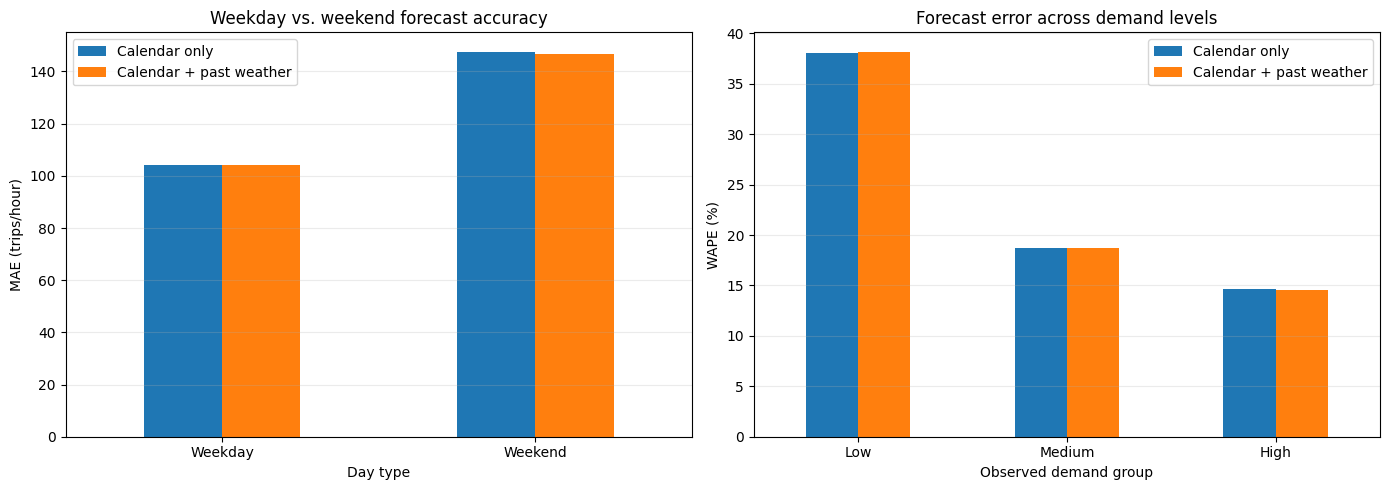

In [ ]:


conditions_dc = rolling_dc.copy()
conditions_dc["date"] = pd.to_datetime(
    conditions_dc["date"]
)

conditions_dc["day_type"] = np.where(
    conditions_dc["date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

conditions_dc["calendar_abs_error"] = (
    conditions_dc["calendar_error"].abs()
)
conditions_dc["weather_abs_error"] = (
    conditions_dc["weather_error"].abs()
)

# Analyze weekday vs. weekend forecasting errors.
weekday_stats = (
    conditions_dc.groupby("day_type")
    .agg(
        calendar_mae=("calendar_abs_error", "mean"),
        weather_mae=("weather_abs_error", "mean"),
        n_hours=("actual", "size")
    )
    .reindex(["Weekday", "Weekend"])
    .dropna(how="all")
)

print("Weekday vs. weekend:")
display(weekday_stats)

# Aggregate forecast errors and demand by day.
daily_conditions = (
    conditions_dc.groupby("date", as_index=False)
    .agg(
        actual_total=("actual", "sum"),
        calendar_abs_total=("calendar_abs_error", "sum"),
        weather_abs_total=("weather_abs_error", "sum"),
        day_type=("day_type", "first")
    )
)

# Group observed days into three equally sized demand groups.
# Demand groups are defined using held-out observations
# for retrospective error analysis, not for forecasting.
daily_conditions["demand_group"] = pd.qcut(
    daily_conditions["actual_total"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

demand_stats = (
    daily_conditions.groupby("demand_group", observed=True)
    .agg(
        n_days=("date", "size"),
        total_actual=("actual_total", "sum"),
        calendar_abs_total=("calendar_abs_total", "sum"),
        weather_abs_total=("weather_abs_total", "sum")
    )
)

# Weighted Absolute Percentage Error (WAPE)
# is more interpretable across different demand volumes.
demand_stats["calendar_wape"] = (
    100 * demand_stats["calendar_abs_total"]
    / demand_stats["total_actual"].replace(0, np.nan)
)
demand_stats["weather_wape"] = (
    100 * demand_stats["weather_abs_total"]
    / demand_stats["total_actual"].replace(0, np.nan)
)

print("Errors by observed demand level:")
display(demand_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekday_stats[["calendar_mae", "weather_mae"]].plot(
    kind="bar", ax=axes[0]
)
axes[0].set(
    title="Weekday vs. weekend forecast accuracy",
    xlabel="Day type",
    ylabel="MAE (trips/hour)"
)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(["Calendar only", "Calendar + past weather"])

demand_stats[["calendar_wape", "weather_wape"]].plot(
    kind="bar", ax=axes[1]
)
axes[1].set(
    title="Forecast error across demand levels",
    xlabel="Observed demand group",
    ylabel="WAPE (%)"
)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Calendar only", "Calendar + past weather"])

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

plot_path = DATA_DIR / 'weekend.png'
fig.savefig(plot_path)


### 12.2 — Forecast horizon and sudden demand changes

Abrupt-change threshold: 391.7 trips/hour


,calendar_mae,weather_mae,n_hours
demand_change_type,,,
Regular change,114.928503,114.869746,4098
Abrupt change,169.029294,168.592825,456


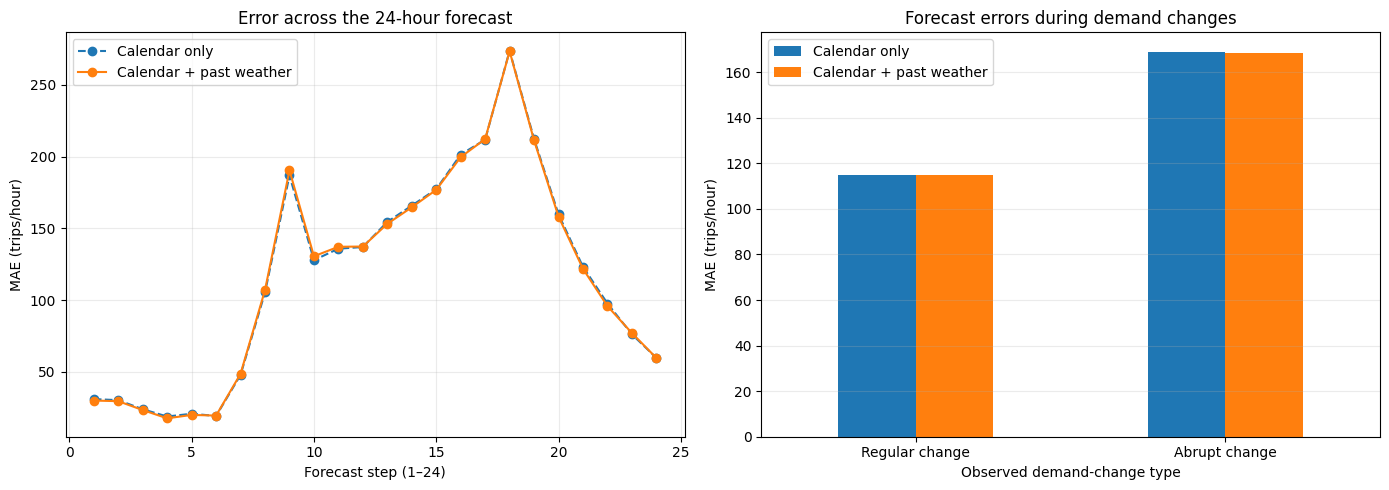

In [ ]:


conditions_dc = conditions_dc.sort_values(
    ["date", "timestamp"]
).copy()

# Position within each 24-hour forecast.
conditions_dc["forecast_step"] = (
    conditions_dc.groupby("date").cumcount() + 1
)

# Forecast error by prediction step.
horizon_stats = (
    conditions_dc.groupby("forecast_step")
    .agg(
        calendar_mae=("calendar_abs_error", "mean"),
        weather_mae=("weather_abs_error", "mean")
    )
)

# Detect abrupt changes in observed hourly demand.
# The first hour of each day has no within-day predecessor.
conditions_dc["actual_hourly_change"] = (
    conditions_dc.groupby("date")["actual"]
    .diff()
    .abs()
)

jump_threshold = conditions_dc[
    "actual_hourly_change"
].quantile(0.90)

shift_data = conditions_dc.dropna(
    subset=["actual_hourly_change"]
).copy()

shift_data["demand_change_type"] = np.where(
    shift_data["actual_hourly_change"] >= jump_threshold,
    "Abrupt change",
    "Regular change"
)

shift_stats = (
    shift_data.groupby("demand_change_type")
    .agg(
        calendar_mae=("calendar_abs_error", "mean"),
        weather_mae=("weather_abs_error", "mean"),
        n_hours=("actual", "size")
    )
    .reindex(["Regular change", "Abrupt change"])
)

print(
    f"Abrupt-change threshold: "
    f"{jump_threshold:.1f} trips/hour"
)

display(shift_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A — Error over the 24 forecast steps
axes[0].plot(
    horizon_stats.index,
    horizon_stats["calendar_mae"],
    "o--",
    label="Calendar only"
)

axes[0].plot(
    horizon_stats.index,
    horizon_stats["weather_mae"],
    "o-",
    label="Calendar + past weather"
)

axes[0].set(
    xlabel="Forecast step (1–24)",
    ylabel="MAE (trips/hour)",
    title="Error across the 24-hour forecast"
)
axes[0].legend()
axes[0].grid(alpha=0.25)

# Plot B — Errors during abrupt vs regular demand changes
shift_stats[["calendar_mae", "weather_mae"]].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set(
    xlabel="Observed demand-change type",
    ylabel="MAE (trips/hour)",
    title="Forecast errors during demand changes"
)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Calendar only", "Calendar + past weather"])
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
plot_path = DATA_DIR / 'demand.png'
fig.savefig(plot_path)

## 13. Findings and Discussion



We investigated the zero-shot forecasting behavior of pretrained TiRex-2 using hourly Capital Bikeshare demand in Washington, DC, from December 2023 to June 2024.

Two configurations were compared:

- **Calendar-only:** 336 hours of historical bike-sharing demand and known calendar covariates.
- **Calendar + Past Weather:** The same inputs, supplemented with 336 hours of historical temperature, precipitation, humidity, and wind speed.

Both configurations predicted the following 24 hours. Model weights remained fixed throughout the experiments.

With `N_BACKTEST_DAYS = None`, all 198 eligible daily forecast origins were evaluated, producing 4,752 held-out hourly predictions.

### Main Findings

**Finding 1 — Historical weather provides negligible overall improvement**

The calendar-only configuration achieved an MAE of 116.63 trips/hour, compared with 116.49 trips/hour when historical weather was included.

The improvement was only 0.134 trips/hour (approximately 0.11%). Historical weather improved daily MAE on 109 of 198 evaluated days.

WAPE also changed minimally, from 20.51% to 20.49%.

These results suggest that historical weather covariates provide little additional predictive value in the current experimental setup.

**Finding 2 — Errors are substantially higher during rainy conditions**

For the calendar + past weather configuration, MAE increased across observed precipitation categories:

- Dry conditions: 107.44 trips/hour (4,298 hours).
- Light rain: 190.40 trips/hour (355 hours).
- More intense rain: 244.30 trips/hour (99 hours).

Adding historical weather slightly worsened accuracy in both rainy categories compared with the calendar-only configuration.

This indicates that rainy periods are associated with greater forecasting difficulty. However, the analysis does not establish that rainfall itself causes the larger errors.

**Finding 3 — Error patterns depend on temperature**

Forecasting accuracy differed across temperature categories.

Historical weather produced small improvements in the 20–30°C and ≥30°C groups, but slightly worsened performance in some colder and moderate-temperature groups.

These improvements were small, and the temperature groups contained unequal numbers of observations.

Therefore, we cannot conclude that historical weather consistently improves forecasts at particular temperatures.

**Finding 4 — Demand regimes reveal systematic difficulties**

Relative forecasting errors were larger on low-demand days:

- Low-demand days: WAPE 38.19%.
- Medium-demand days: WAPE 18.68%.
- High-demand days: WAPE 14.55%.

The weather-conditioned model also showed higher MAE on weekends (146.85 trips/hour) than weekdays (104.22 trips/hour).

Hours with abrupt changes in observed demand had a higher MAE (168.59) than hours with regular changes (114.87).

These findings suggest that demand magnitude and rapid changes are important dimensions of the model's forecasting behavior.

**Finding 5 — Probabilistic forecasts show approximately nominal coverage**

TiRex-2 produces quantile forecasts, allowing us to evaluate prediction uncertainty.

The empirical coverage of the p10–p90 interval was 78.6%, compared with the nominal 80% coverage.

Overall coverage is reasonably close to the nominal level, but calibration may differ across weather conditions, time periods, and demand regimes.

### Limitations

- The evaluation covers approximately seven months, rather than multiple complete years.
- Future observed weather was used only for retrospective error analysis, not as a forecasting input.
- Rainfall and temperature categories have unequal sample sizes.
- Higher MAE in particular conditions may partly reflect differences in demand magnitude or hour of day.
- The analysis is observational and cannot establish causal relationships.
- Forecasts start at local midnight, so forecast step and hour of day are confounded.
- Overlapping historical contexts make neighboring forecasting windows statistically dependent.
- No formal statistical significance test was performed for the small difference between configurations.
- Negative lower-quantile predictions are possible, even though bike-sharing counts cannot be negative.

### Conclusion and Future Directions

Our main finding is that adding historical weather covariates to TiRex-2 provides negligible improvement in overall zero-shot forecasting accuracy.

Nevertheless, forecasting errors differ substantially across rainfall conditions, demand levels, and abrupt demand changes.

This suggests that weather-related evaluation and demand-regime analysis are more informative for understanding model behavior than aggregate MAE alone.

Future investigations could include seasonal comparisons, evaluation using forecasted future weather covariates, and a more detailed examination of systematic errors during unusual demand conditions.


In [ ]:

# Section 13 — Summary of evaluated results
# Uses existing notebook outputs; no new TiRex-2 inference.

from IPython.display import display

n_days = rolling_dc["date"].nunique()
n_hours = len(rolling_dc)

calendar_mae = rolling_dc["calendar_error"].abs().mean()
weather_mae = rolling_dc["weather_error"].abs().mean()

actual_sum = rolling_dc["actual"].sum()

calendar_wape = (
    100 * rolling_dc["calendar_error"].abs().sum()
    / actual_sum
)
weather_wape = (
    100 * rolling_dc["weather_error"].abs().sum()
    / actual_sum
)

improvement = calendar_mae - weather_mae
coverage = 100 * rolling_dc["inside_p10_p90"].mean()

days_improved = (
    daily_dc["weather_improvement"] > 0
).sum()

summary_df = pd.DataFrame({
    "Metric": [
        "MAE (trips/hour)",
        "WAPE (%)"
    ],
    "Calendar only": [
        calendar_mae,
        calendar_wape
    ],
    "Calendar + past weather": [
        weather_mae,
        weather_wape
    ]
})

print("FINAL PHASE I RESULTS")
print("=" * 50)
print(f"Evaluated days: {n_days}")
print(f"Evaluated hours: {n_hours}")
print()

display(summary_df.round(3))

print(f"MAE improvement: {improvement:+.3f} trips/hour")
print(f"Days improved: {days_improved}/{n_days}")
print(f"p10-p90 coverage: {coverage:.1f}%")

print("\nPRECIPITATION ANALYSIS")
display(rain_stats_dc.round(2))

print("\nTEMPERATURE ANALYSIS")
display(temp_stats_dc.round(2))

print("\nWEEKDAY / WEEKEND")
display(weekday_stats.round(2))

print("\nDEMAND LEVELS")
display(
    demand_stats[
        ["n_days", "calendar_wape", "weather_wape"]
    ].round(2)
)

print("\nABRUPT DEMAND CHANGES")
display(shift_stats.round(2))


FINAL PHASE I RESULTS
Evaluated days: 198
Evaluated hours: 4752



,Metric,Calendar only,Calendar + past weather
0,MAE (trips/hour),116.625,116.492
1,WAPE (%),20.511,20.488


MAE improvement: +0.134 trips/hour
Days improved: 109/198
p10-p90 coverage: 78.6%

PRECIPITATION ANALYSIS


,rain_category,n_hours,calendar_mae,weather_mae,mean_improvement
0,Dry (<=0.2 mm),4298,107.87,107.44,0.43
1,Light rain (0.2–2 mm),355,187.98,190.40,-2.42
2,More rain (>2 mm),99,240.73,244.30,-3.57



TEMPERATURE ANALYSIS


,temp_category,n_hours,calendar_mae,weather_mae,mean_improvement
0,<0°C,463,81.86,82.40,-0.54
1,0–10°C,1766,92.91,92.80,0.10
2,10–20°C,1503,140.85,141.44,-0.59
3,20–30°C,894,139.04,137.56,1.48
4,>=30°C,126,128.89,126.71,2.18


... (2 outputs left out)


DEMAND LEVELS


,n_days,calendar_wape,weather_wape
demand_group,,,
Low,66,38.07,38.19
Medium,66,18.68,18.68
High,66,14.65,14.55



ABRUPT DEMAND CHANGES


,calendar_mae,weather_mae,n_hours
demand_change_type,,,
Regular change,114.93,114.87,4098
Abrupt change,169.03,168.59,456


## 14. AI4VIS — Generative AI Usage and Reflection



This investigation was conducted as part of the AI-aided pair in the AI and Visualization Lab.

Generative AI (ChatGPT) was used to support experimental design, notebook development, data preparation, debugging, visualization, and interpretation of model behavior.

The AI-generated suggestions were evaluated through actual code execution and comparison with the resulting data and visualizations.

Important AI interactions, including prompts, responses, corrections, accepted or modified suggestions, and critical reflections, are documented separately in the accompanying AI interaction PDF.

This notebook focuses on the experimental methodology, visual analysis, and empirical findings.
